In [2]:
import pandas as pd
import torch
print(torch.__version__)


2.14.1+cpu


In [5]:
train_df=pd.read_csv('../data/mitbih_train.csv',header=None)
test_df=pd.read_csv('../data/mitbih_test.csv',header=None)
train_df.shape,test_df.shape

((87554, 188), (21892, 188))

In [6]:
X_train = train_df.iloc[:, :-1]
y_train = train_df.iloc[:, -1].astype(int)

X_test = test_df.iloc[:, :-1]
y_test = test_df.iloc[:, -1].astype(int)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(87554, 187) (87554,)
(21892, 187) (21892,)


In [7]:
class_names = ['Normal', 'Supraventricular', 'Ventricular', 'Fusion', 'Unknown']

counts = y_train.value_counts().sort_index()
percentages = y_train.value_counts(normalize=True).sort_index() * 100

print(counts)
print(percentages.round(2))

187
0    72471
1     2223
2     5788
3      641
4     6431
Name: count, dtype: int64
187
0    82.77
1     2.54
2     6.61
3     0.73
4     7.35
Name: proportion, dtype: float64


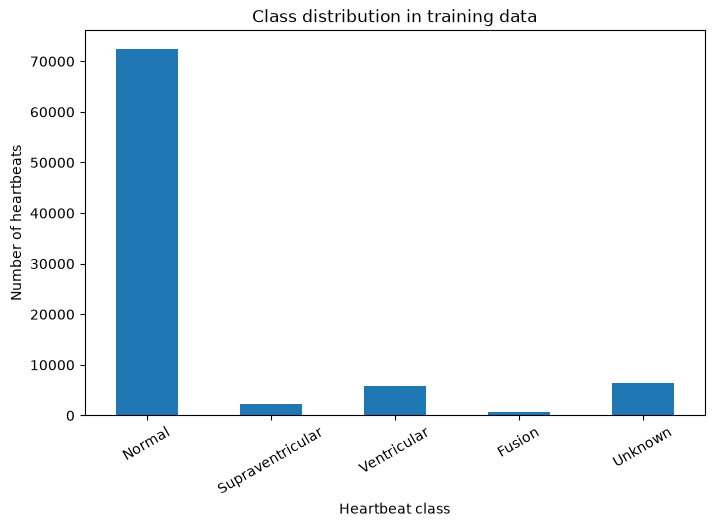

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
counts.plot(kind='bar')
plt.xticks(ticks=range(5), labels=class_names, rotation=30)
plt.title('Class distribution in training data')
plt.xlabel('Heartbeat class')
plt.ylabel('Number of heartbeats')
plt.show()

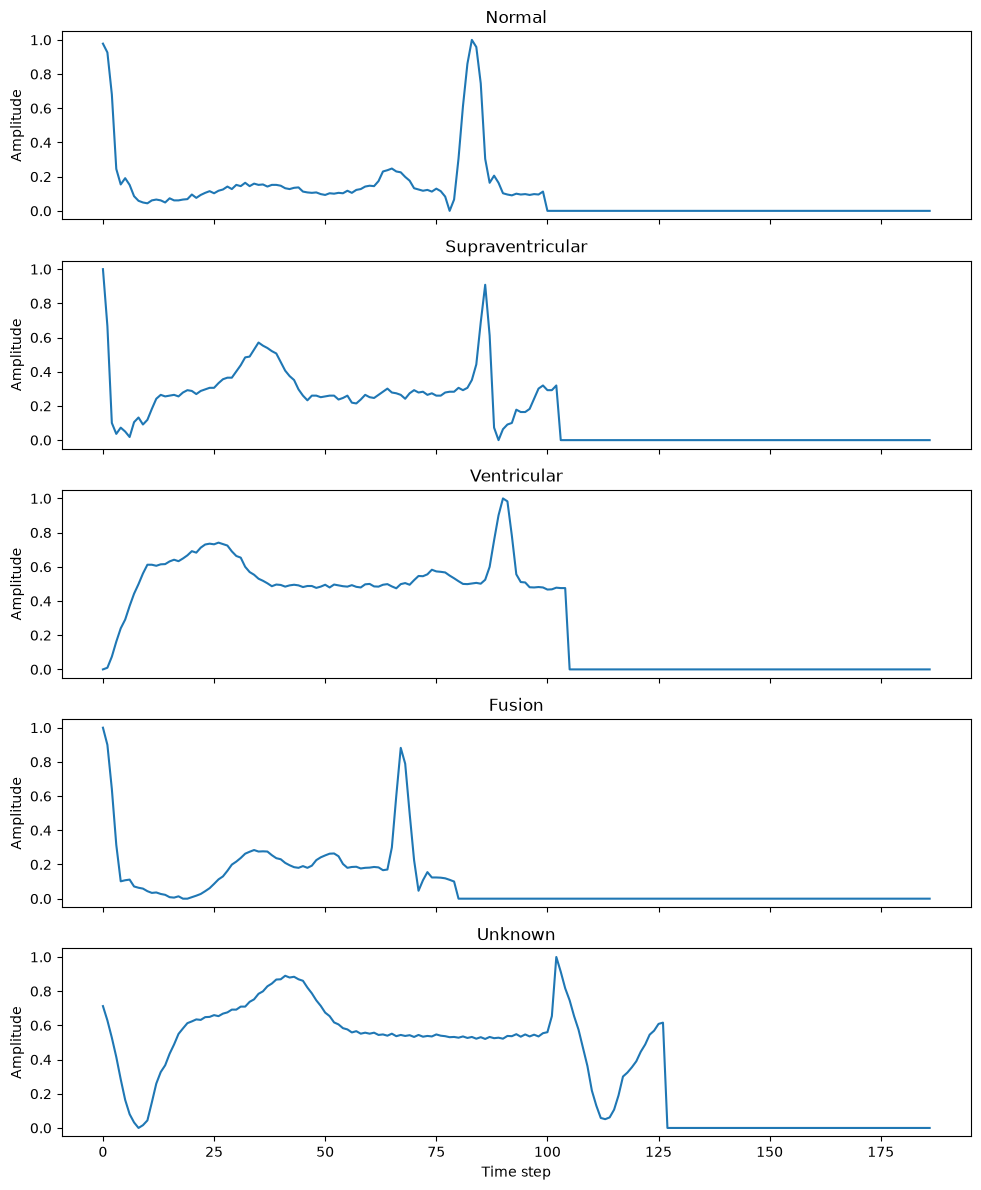

In [11]:
fig, axes = plt.subplots(5, 1, figsize=(10, 12), sharex=True)

for label in range(5):
    first_index = y_train[y_train == label].index[0]
    axes[label].plot(X_train.loc[first_index].values)
    axes[label].set_title(class_names[label])
    axes[label].set_ylabel('Amplitude')

axes[-1].set_xlabel('Time step')
plt.tight_layout()
plt.show()

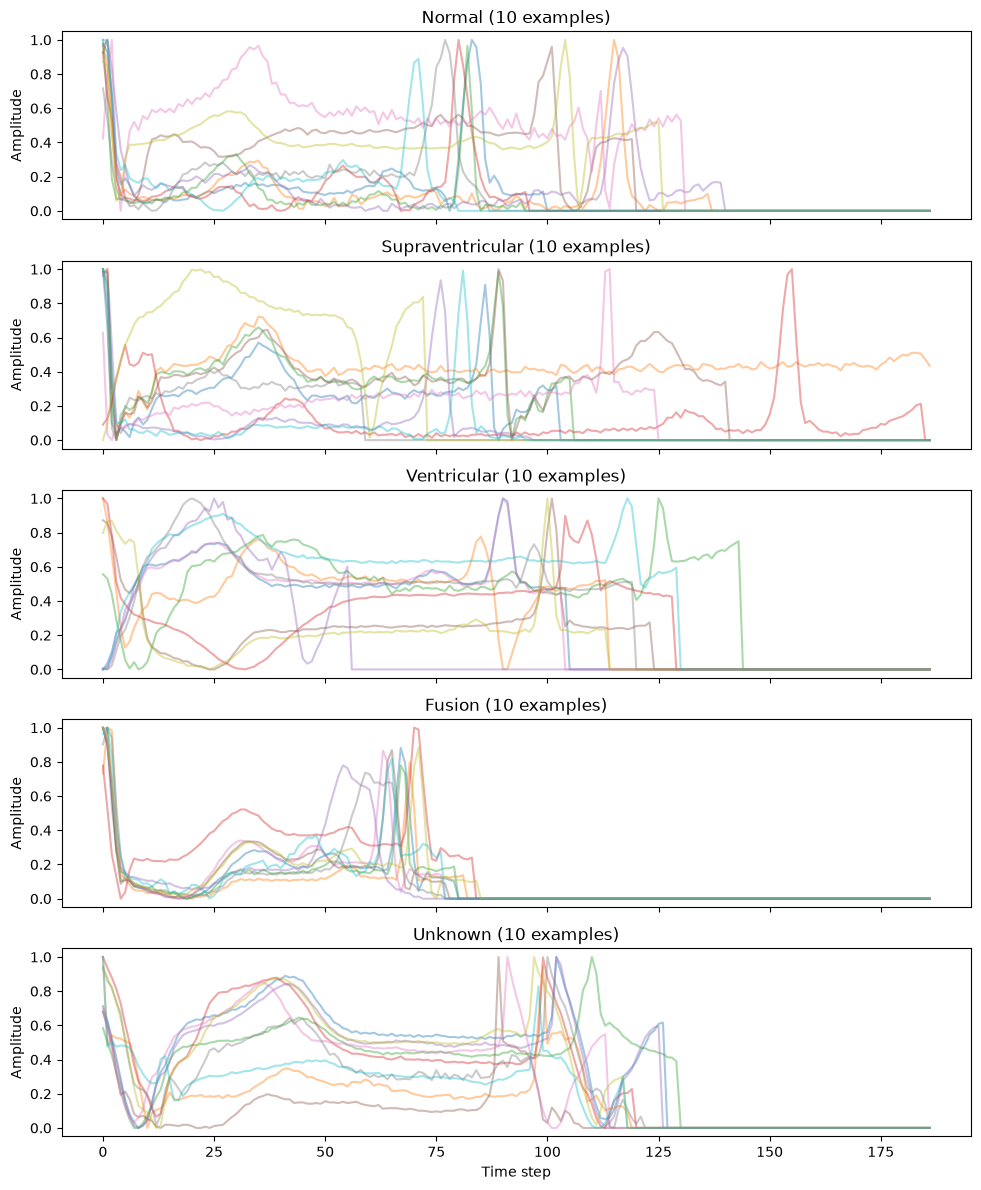

In [12]:
fig, axes = plt.subplots(5, 1, figsize=(10, 12), sharex=True)

for label in range(5):
    class_indices = y_train[y_train == label].index[:10]
    for idx in class_indices:
        axes[label].plot(X_train.loc[idx].values, alpha=0.4)
    axes[label].set_title(f'{class_names[label]} (10 examples)')
    axes[label].set_ylabel('Amplitude')

axes[-1].set_xlabel('Time step')
plt.tight_layout()
plt.show()

## Observations from data exploration

**Dataset size**
- Train: 87,554 heartbeats, Test: 21,892 heartbeats
- Each heartbeat = 187 signal values + 1 label (5 classes)

**Class imbalance**
- Normal: 82.77% | Unknown: 7.35% | Ventricular: 6.61% | Supraventricular: 2.54% | Fusion: 0.73%
- About 113 Normal beats for every Fusion beat.
- A model that always predicts "Normal" would get 82.77% accuracy while
  detecting zero arrhythmias, so accuracy is misleading here.
  I'll use per-class recall and macro-F1 instead.

**Zero padding**
- Heartbeats have different lengths (heart rate varies), but the model needs
  fixed-size input, so each beat is padded with zeros up to 187 values.
- The zeros carry no information, but where the real signal ends hints at heart rate.

**How the classes look**
- Normal: sharp narrow spike, low flat baseline, but spike position varies a lot.
- Ventricular: broad, wide hump with a high baseline, clearly different from Normal.
- Supraventricular: very similar to Normal, and inconsistent across examples.
- Fusion: [update after random sampling]
- Unknown: very consistent, distinctive shape (largely paced beats).

**Expected challenges**
- Supraventricular will likely be the hardest class: rare (2.54%) and similar to Normal.
- Fusion is the rarest class (641 training examples).
- Large variation within classes, so simple rules won't work; a CNN can detect
  patterns wherever they appear in the signal.
  